# Ramen on ImageNet-C: evaluation and failure analysis

Runs **Ramen** and a **NoAdapt** baseline (zero-shot CLIP ViT-B/16) on exactly the same test stream, then breaks down where Ramen helps and where it fails. Same analysis as `cifar100c_ramen.ipynb`, on ImageNet-C at severity 5: 15 corruptions of the same 5,000 ImageNet validation images (the repo's `ImageNetC5K` subset), 1000 classes, 75k images in the stream. Ramen uses the repo's `cfg/ImageNetC5K/Ramen.yaml` (capacity 75, top-1 neighbour, beta 0).
ImageNet has no superclass grouping here, so the class heatmaps are per class and there is no error-granularity section.
The code lives in `ramen_analysis.py` (`ImageNetC5KExperiment`). Results are cached in `results/`, so you can re-run the plot cells without re-running the models.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

import pandas as pd
from ramen_analysis import ImageNetC5KExperiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = ImageNetC5KExperiment(
    model='clip_vitbase16',  # the repo's run_ramen.sh uses ViT-L/14 here, which does not fit Ramen on a 24 GB GPU
    tta_mode='mixed',        # 'mixed': one shuffled stream over all corruptions | 'single': each corruption separately, reset between
    batch_size=100,
    n_per_domain=None,       # None = all 5,000 images per corruption; e.g. 1000 for a quick run (same subset for every corruption)
    seed=0,
    num_workers=16,          # images are JPEGs read from disk, unlike the in-memory CIFAR arrays
).load()

ImageNetC5K: 15 corruptions x 5000 images, 1000 classes, model=clip_vitbase16, mode=mixed


In [3]:
acc = exp.evaluate(capture_probs=True, capture_features=True)   # pass use_cache=False to force a re-run
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,15.00,22.24,7.24
shot_noise,16.88,23.18,6.30
impulse_noise,15.36,23.64,8.28
defocus_blur,25.68,28.52,2.84
glass_blur,16.90,24.20,7.30
motion_blur,26.82,32.88,6.06
zoom_blur,24.58,29.76,5.18
snow,34.00,37.40,3.40
frost,33.02,34.98,1.96
fog,39.18,44.14,4.96


## 1. Which corruptions does Ramen struggle on?
Orange = NoAdapt, blue = Ramen, so the line between them is what adaptation changes. Corruptions are sorted with Ramen's worst at the top. **Bold** numbers on the right are corruptions where Ramen does *worse* than doing nothing.

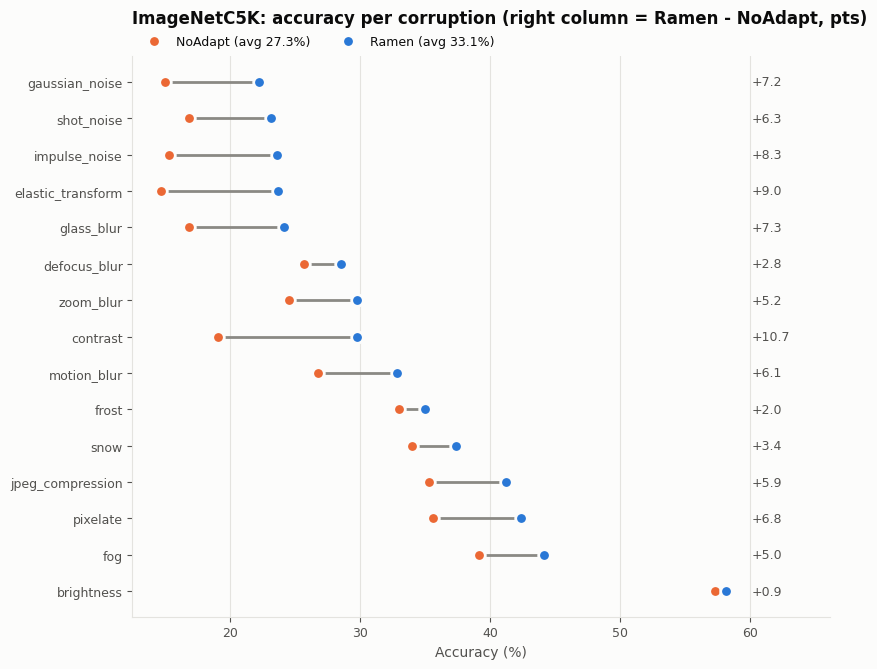

In [4]:
exp.plot_domain_accuracy();

## 2. Per-sample flips
The aggregate gain hides two opposing effects. Blue = samples Ramen **fixed** (NoAdapt wrong, Ramen right). Red = samples Ramen **broke** (NoAdapt right, Ramen wrong). A large red bar means harmful adaptation, even when the net gain is positive.

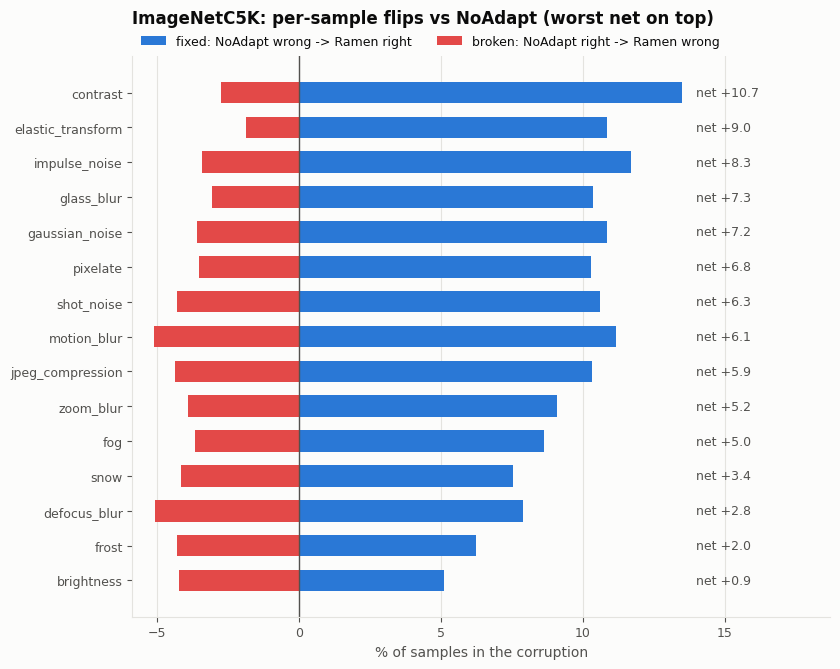

In [5]:
exp.plot_flips();

## 3. Which classes, under which corruptions?
Ramen − NoAdapt accuracy per class and corruption, for the 30 classes Ramen hurts most on average (red = adaptation hurts). The second heatmap shows Ramen's absolute accuracy for the 30 classes where it is worst. Each class has only ~5 images per corruption, so single cells are noisy; the row averages are more reliable.

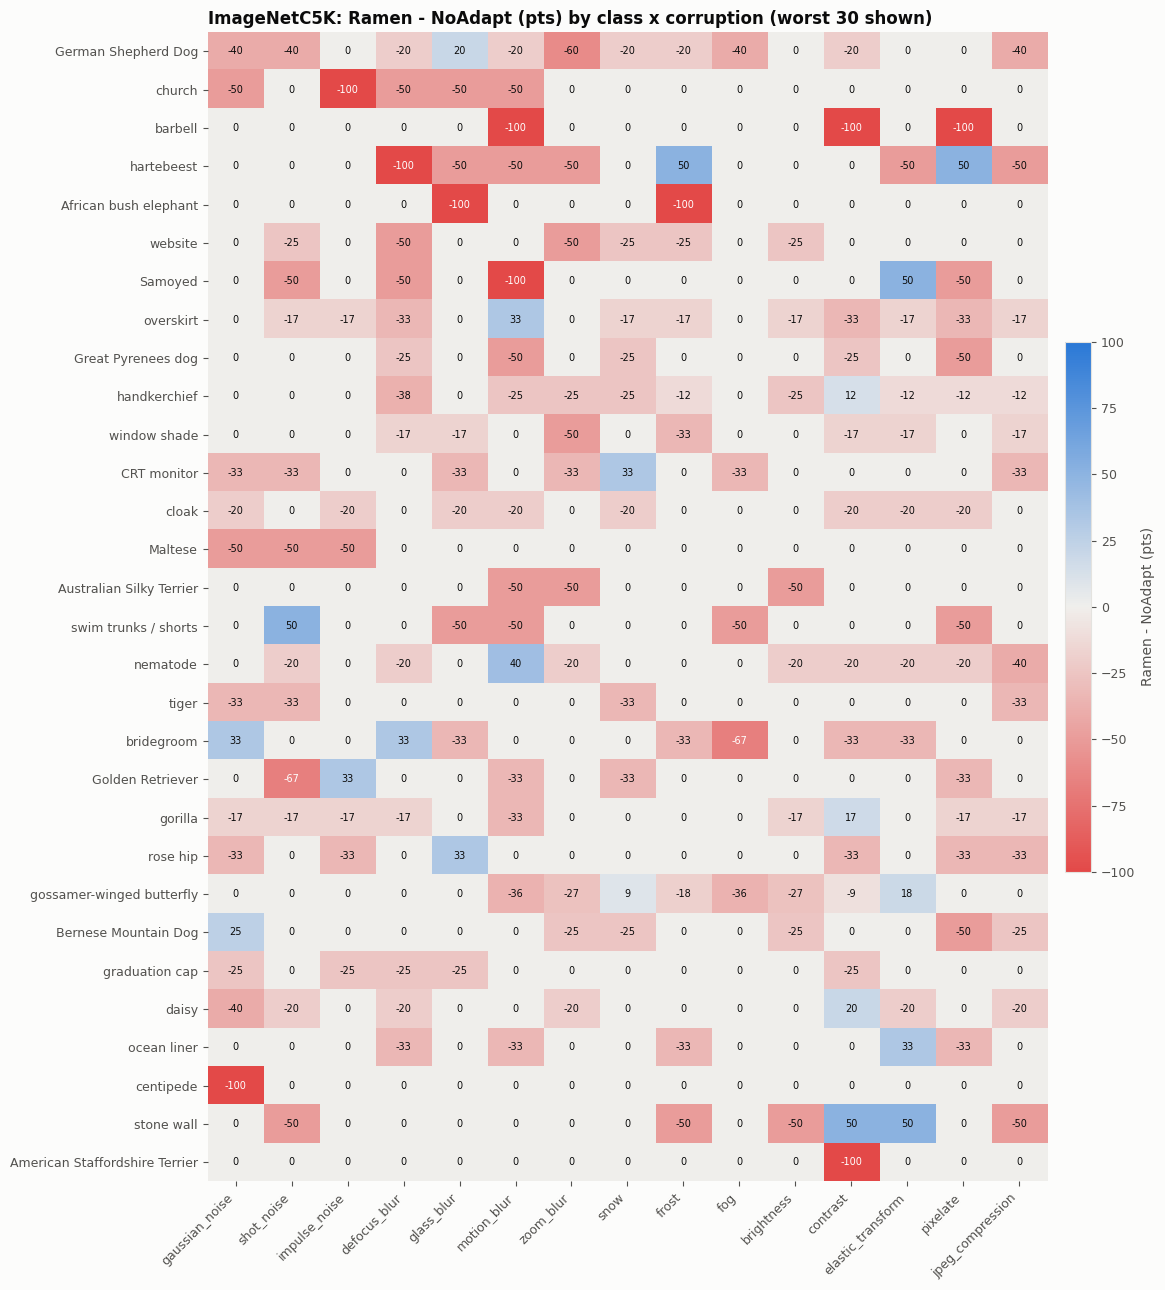

In [6]:
exp.plot_class_heatmap('delta', max_rows=30);

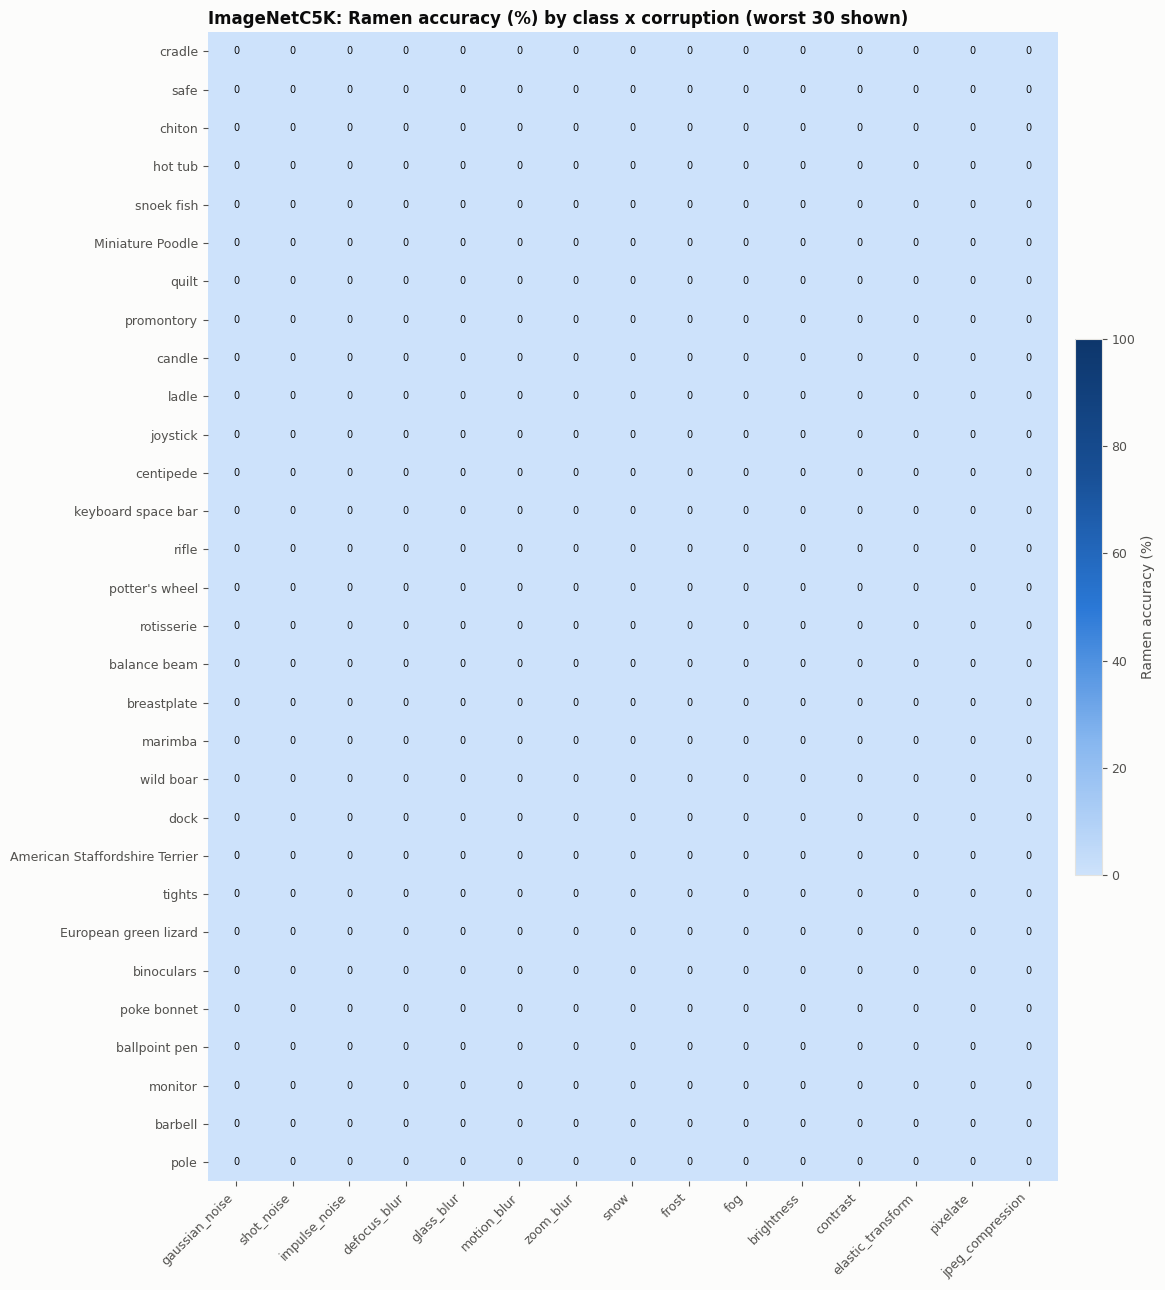

In [7]:
exp.plot_class_heatmap('Ramen', max_rows=30);

Per-class Ramen − NoAdapt accuracy over all corruptions, as a table: the classes adaptation hurts most and helps most.

In [8]:
r, b = exp.results['Ramen'], exp.results['NoAdapt']
per_class = pd.DataFrame({'NoAdapt': b.groupby('label')['correct'].mean() * 100,
                          'Ramen': r.groupby('label')['correct'].mean() * 100,
                          'samples': r.groupby('label').size()})
per_class['delta'] = per_class['Ramen'] - per_class['NoAdapt']
per_class.index = [exp.classes[i] for i in per_class.index]
per_class = per_class.sort_values('delta').round(2)
display(per_class.head(10))
per_class.tail(10)

,NoAdapt,Ramen,samples,delta
church,40.00,20.00,30,-20.00
barbell,20.00,0.00,15,-20.00
German Shepherd Dog,33.33,13.33,75,-20.00
hartebeest,56.67,40.00,30,-16.67
website,51.67,38.33,60,-13.33
African bush elephant,93.33,80.00,15,-13.33
Samoyed,33.33,20.00,30,-13.33
overskirt,33.33,21.11,90,-12.22
Great Pyrenees dog,35.00,23.33,60,-11.67
handkerchief,22.50,10.83,120,-11.67


,NoAdapt,Ramen,samples,delta
cougar,28.89,55.56,45,26.67
gondola,28.89,55.56,45,26.67
fire salamander,50.00,76.67,60,26.67
scorpion,28.89,57.78,45,28.89
ruffed grouse,35.56,64.44,45,28.89
manhole cover,40.00,68.89,45,28.89
Dandie Dinmont Terrier,31.67,61.67,60,30.00
water tower,53.33,83.33,30,30.00
rain barrel,28.00,60.00,75,32.00
stove,40.00,73.33,30,33.33


## 4. Prediction bias / class collapse
Predicted share of each class minus its true share. Entropy-driven TTA tends to collapse onto a few "attractor" classes, which show up as large positive bars for Ramen.

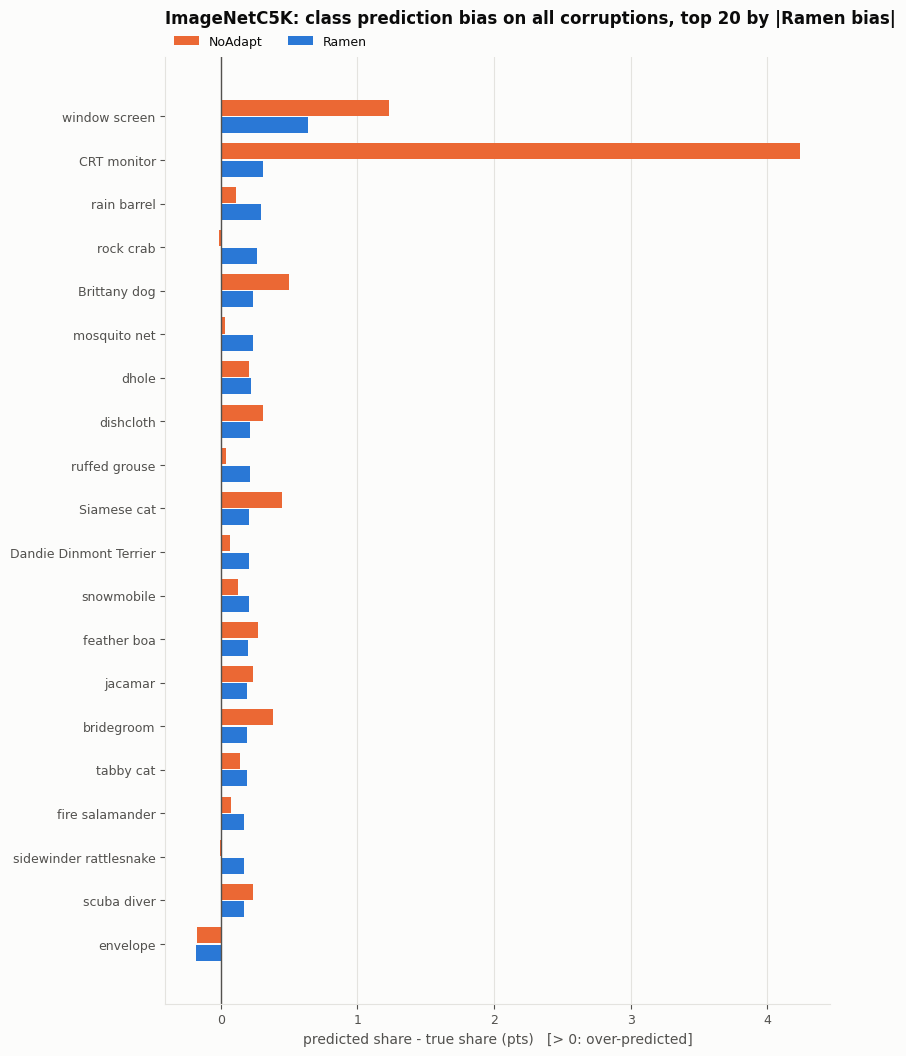

In [9]:
exp.plot_prediction_bias();

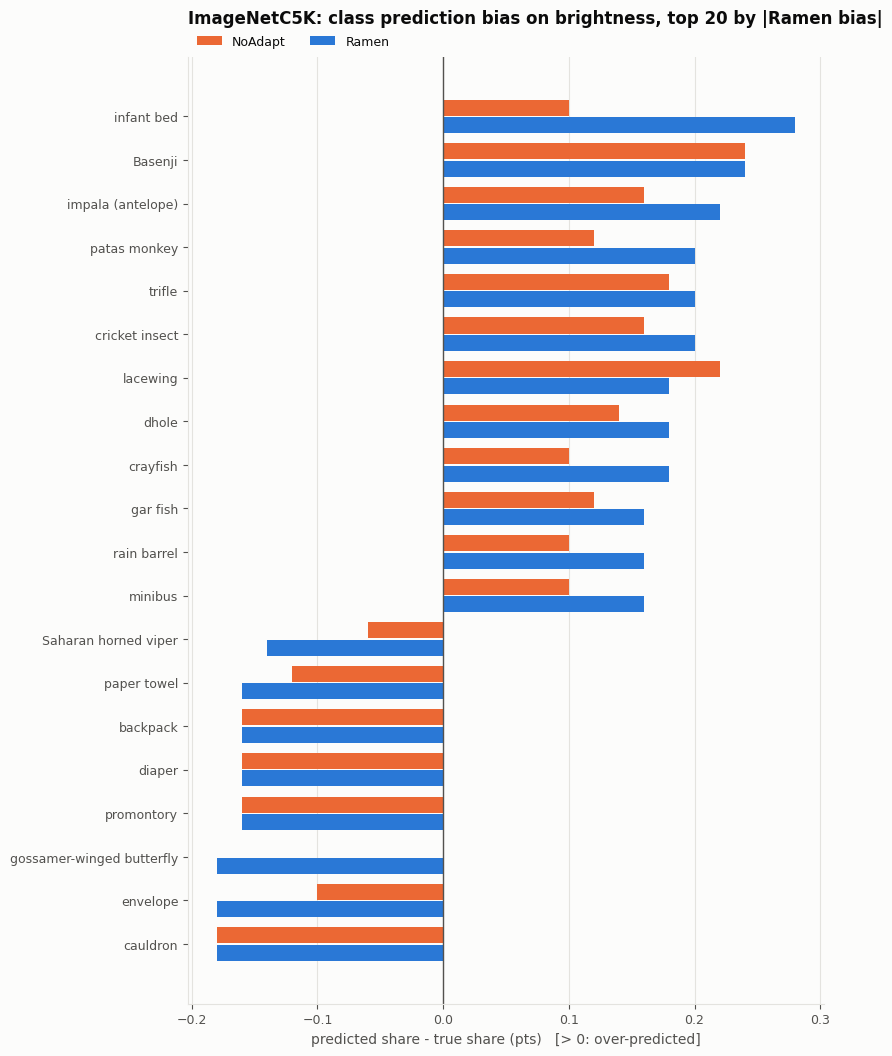

In [10]:
exp.plot_prediction_bias(domain=acc.drop('average')['delta'].idxmin());  # the corruption where Ramen gains least

## 5. What gets confused with what
A 1000×1000 matrix is unreadable, so these are the most frequent `true -> predicted` errors, with each one's share of the true class.

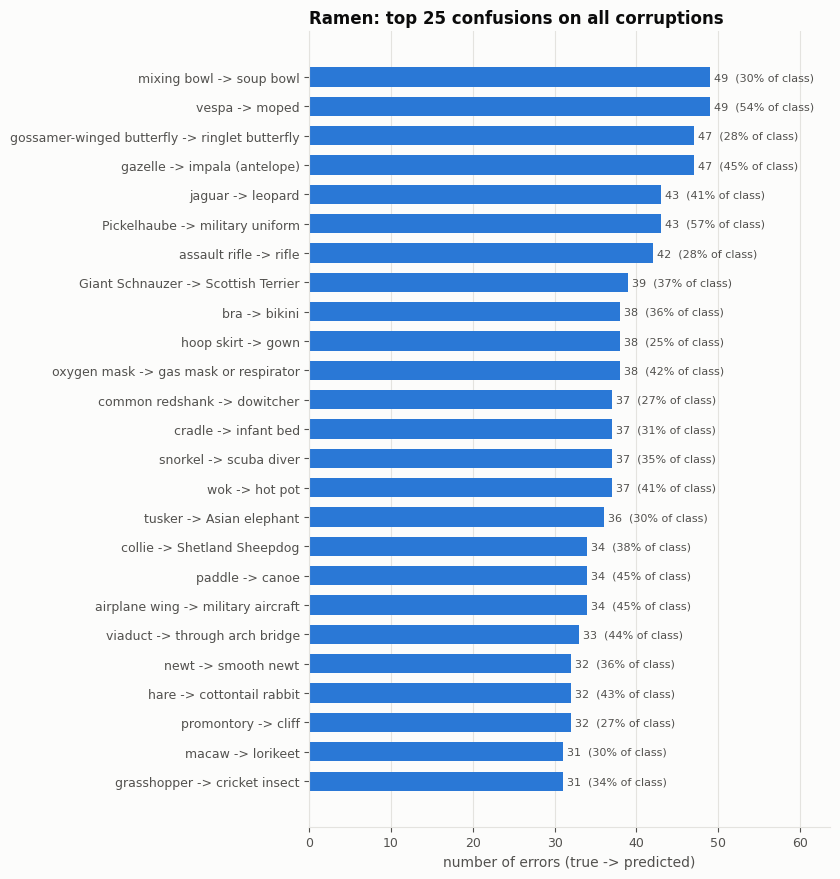

In [11]:
exp.plot_confusion();

worst corruption for Ramen: gaussian_noise


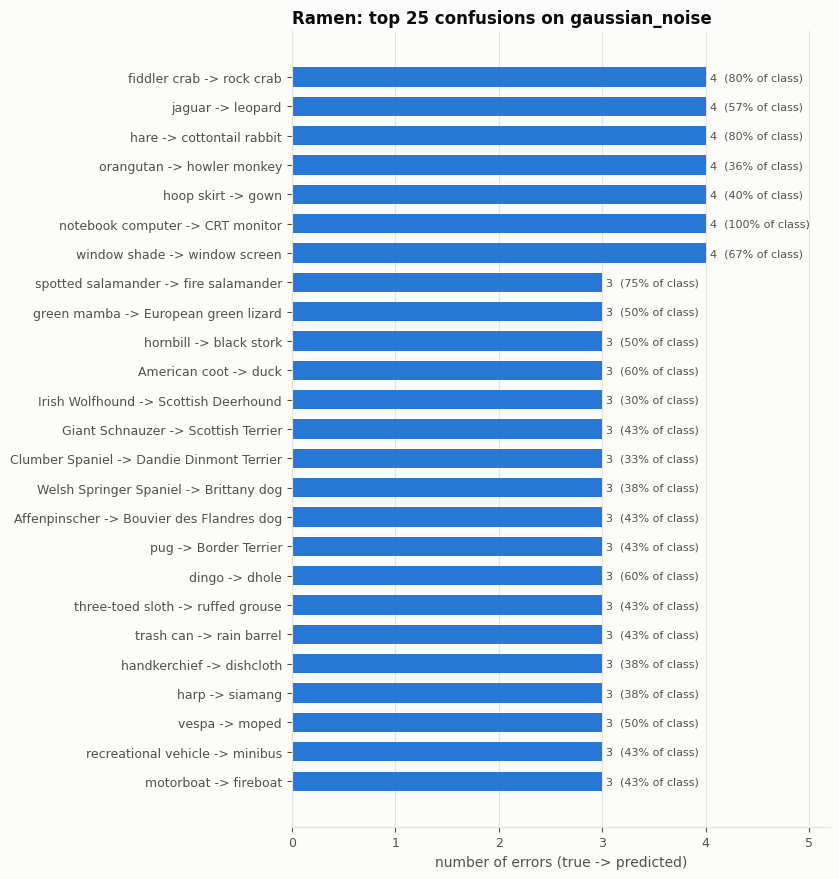

In [12]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst corruption for Ramen:', worst)
exp.plot_confusion(domain=worst);

## 6. Does Ramen degrade over time?
Top panel: rolling accuracy along the stream. Bottom panel: rolling Ramen − NoAdapt gap. A gap that shrinks or turns red later in the stream points to cache staleness or error accumulation. The stream has 75k samples, so Ramen's fp16 cache priorities overflow (after 65,520 samples) only in the last ~13% of it.

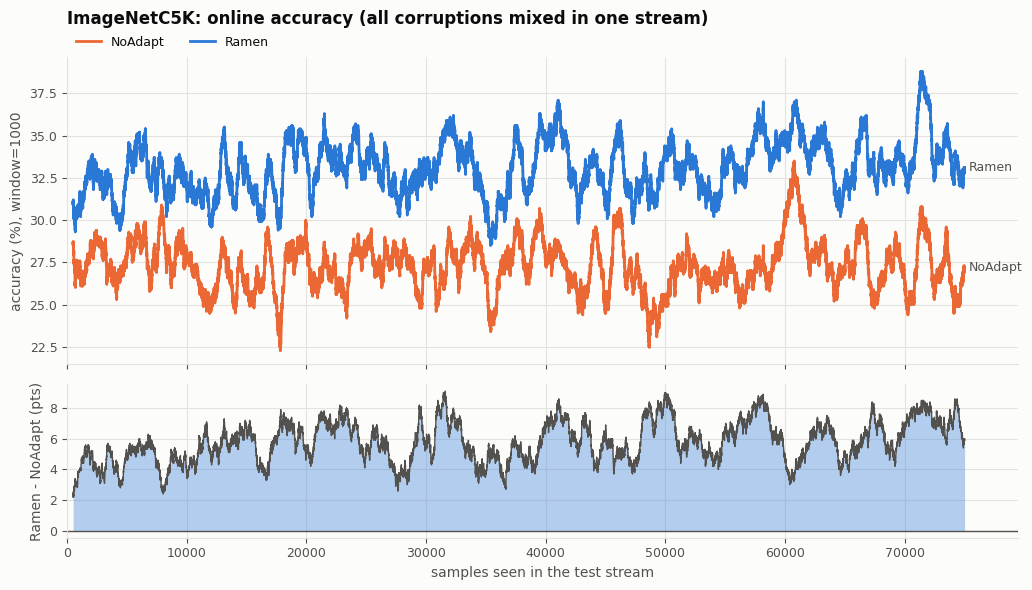

In [13]:
exp.plot_online_accuracy();

## 7. Calibration
Left: points below the diagonal mean the model is overconfident. Right: Ramen's confidence on wrong predictions. Errors made at high confidence are the most dangerous failures, because a confidence threshold won't catch them.

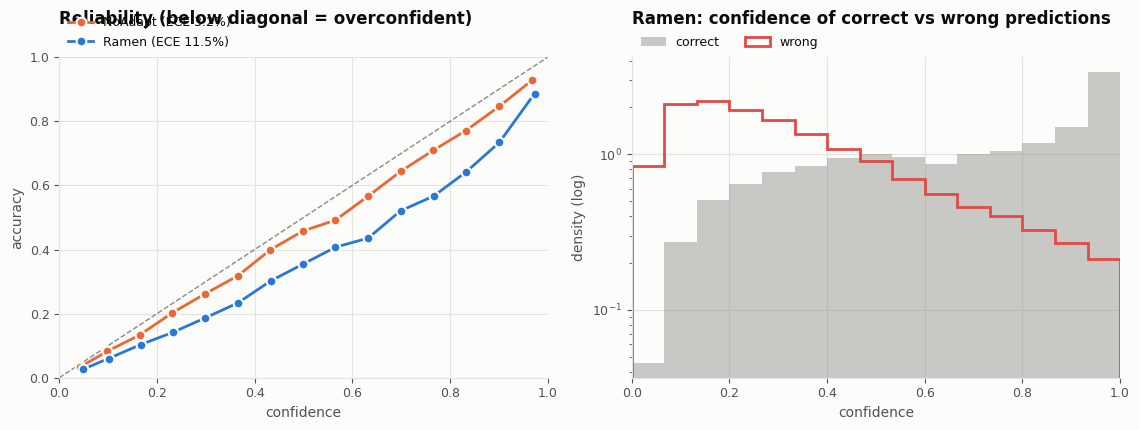

In [14]:
exp.plot_calibration();

## 8. Look at the failures
Images are sorted most-confident first. Captions show the corruption, the true class, and Ramen's prediction with its confidence.
`kind`: `'broken'` (Ramen broke a correct zero-shot prediction), `'both wrong'`, `'fixed'`, or `'wrong'` (any Ramen error).

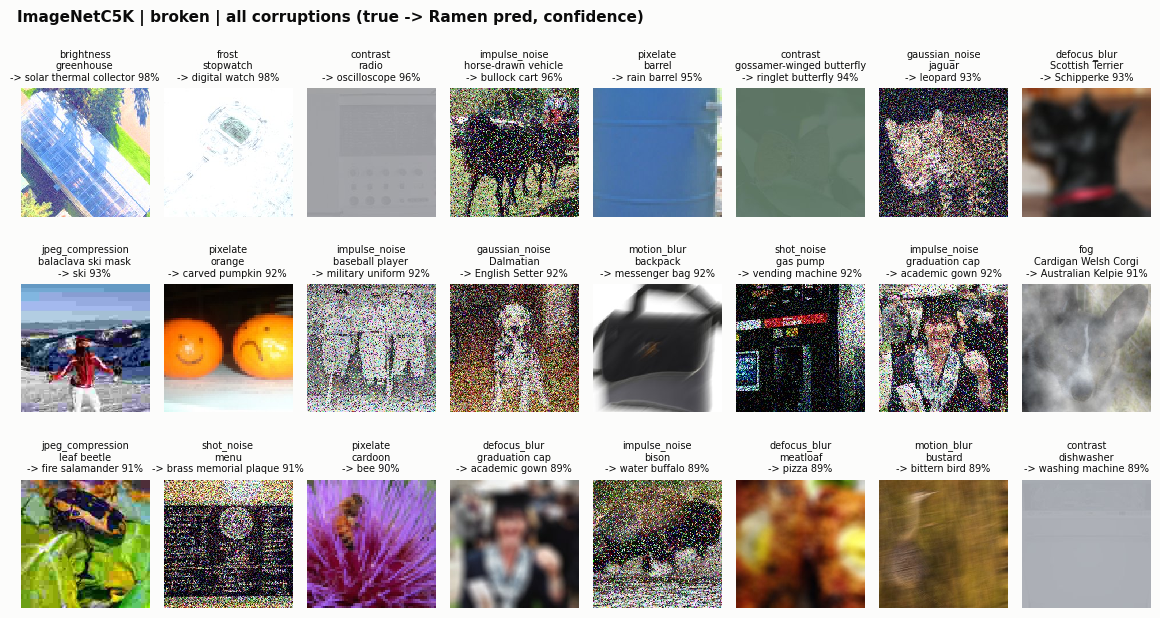

In [15]:
exp.show_failures(kind='broken', n=24);

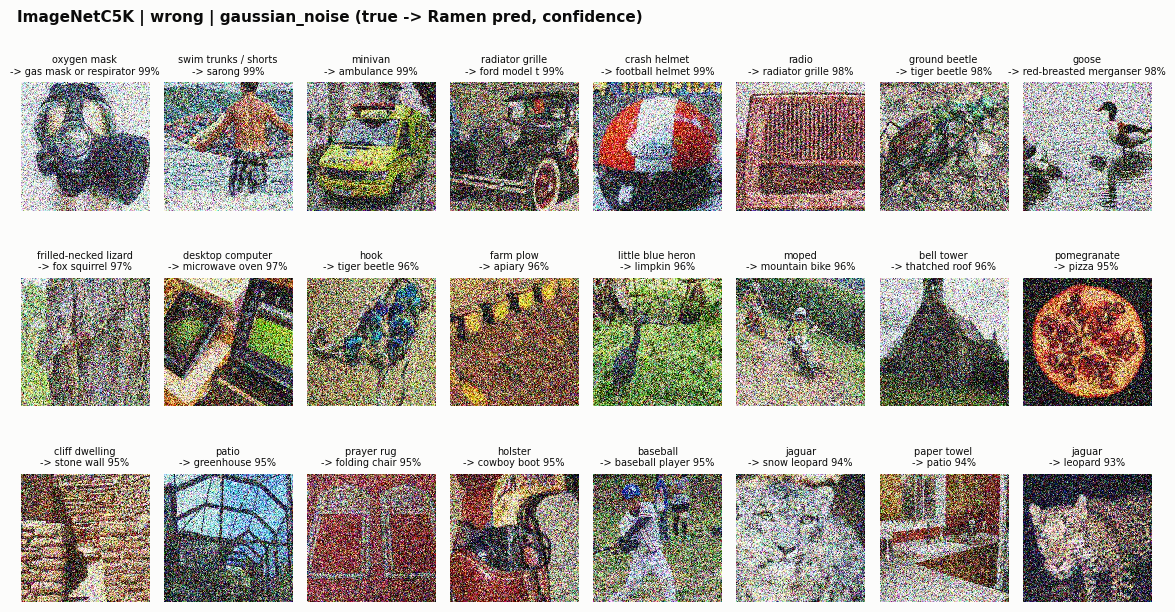

In [16]:
exp.show_failures(domain=worst, kind='wrong', n=24);

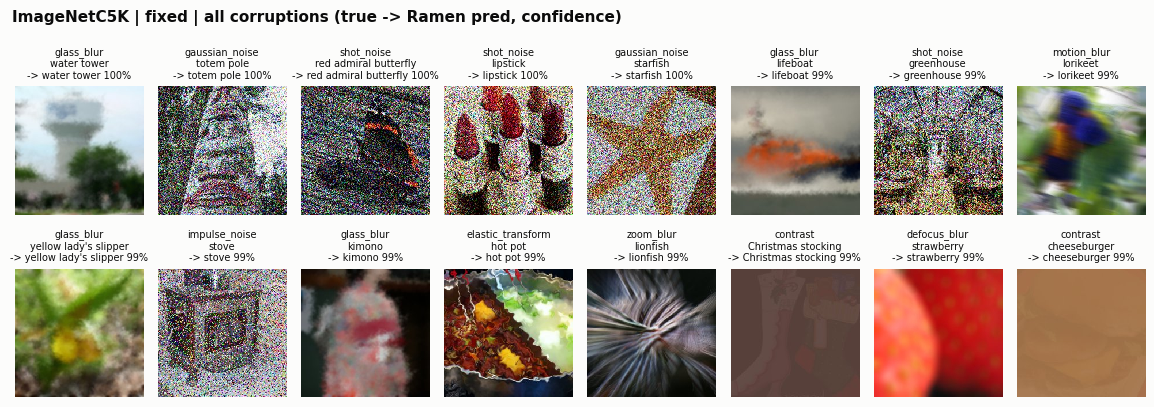

In [17]:
exp.show_failures(kind='fixed', n=16);

Images for the most confused pairs, one row per pair. A row labelled `true: A / Ramen: B` shows images whose true class is A that Ramen predicts as B. Each caption gives the corruption, Ramen's confidence in B, and what NoAdapt did on the same image: `right` (it predicted A), `same error` (it also predicted B), or the other wrong class it picked.
`order='confident'` shows the errors Ramen is surest about first; `order='borderline'` shows the ones where it barely picked B (low confidence, so other classes were close behind).

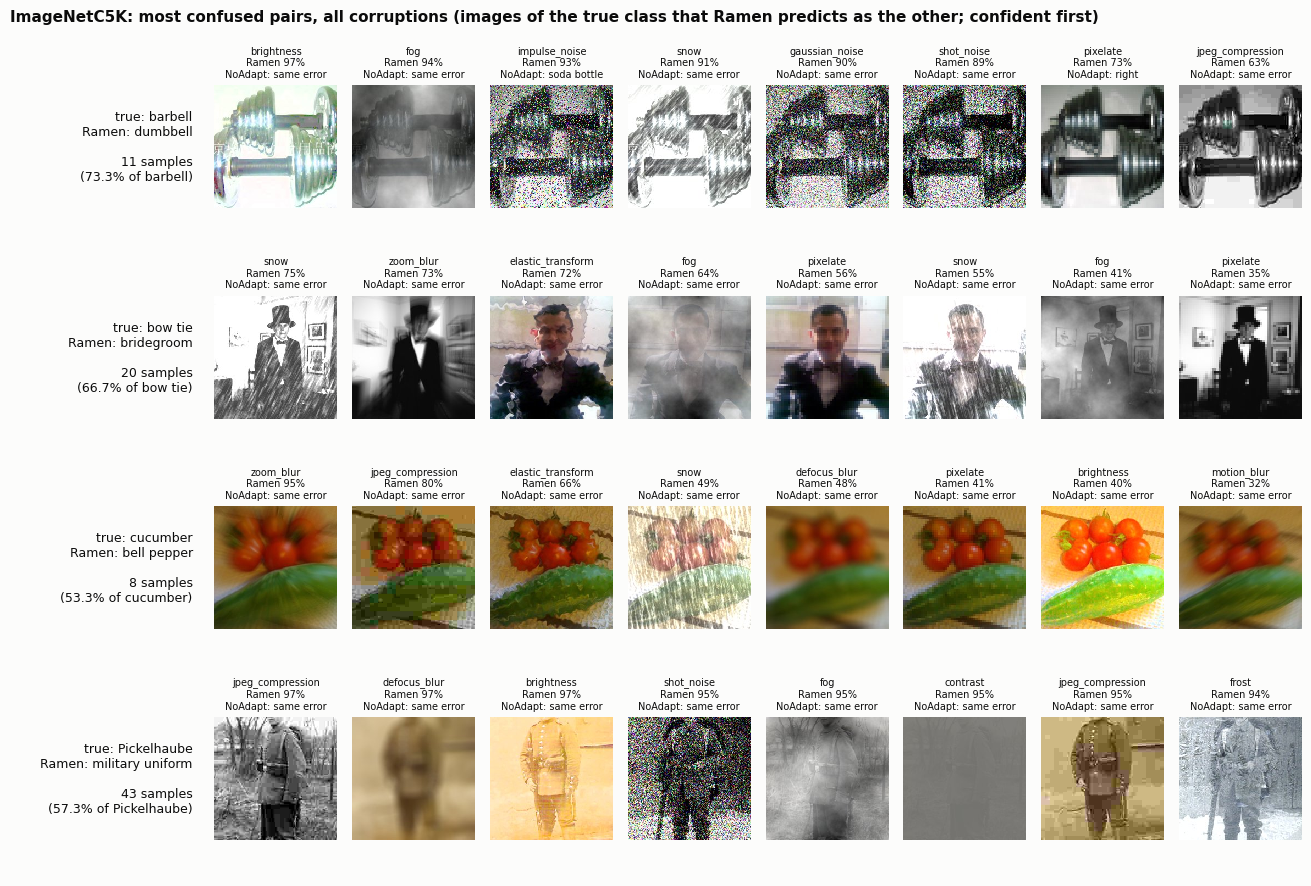

In [18]:
exp.show_confused_pairs(top_k=4, n=8);

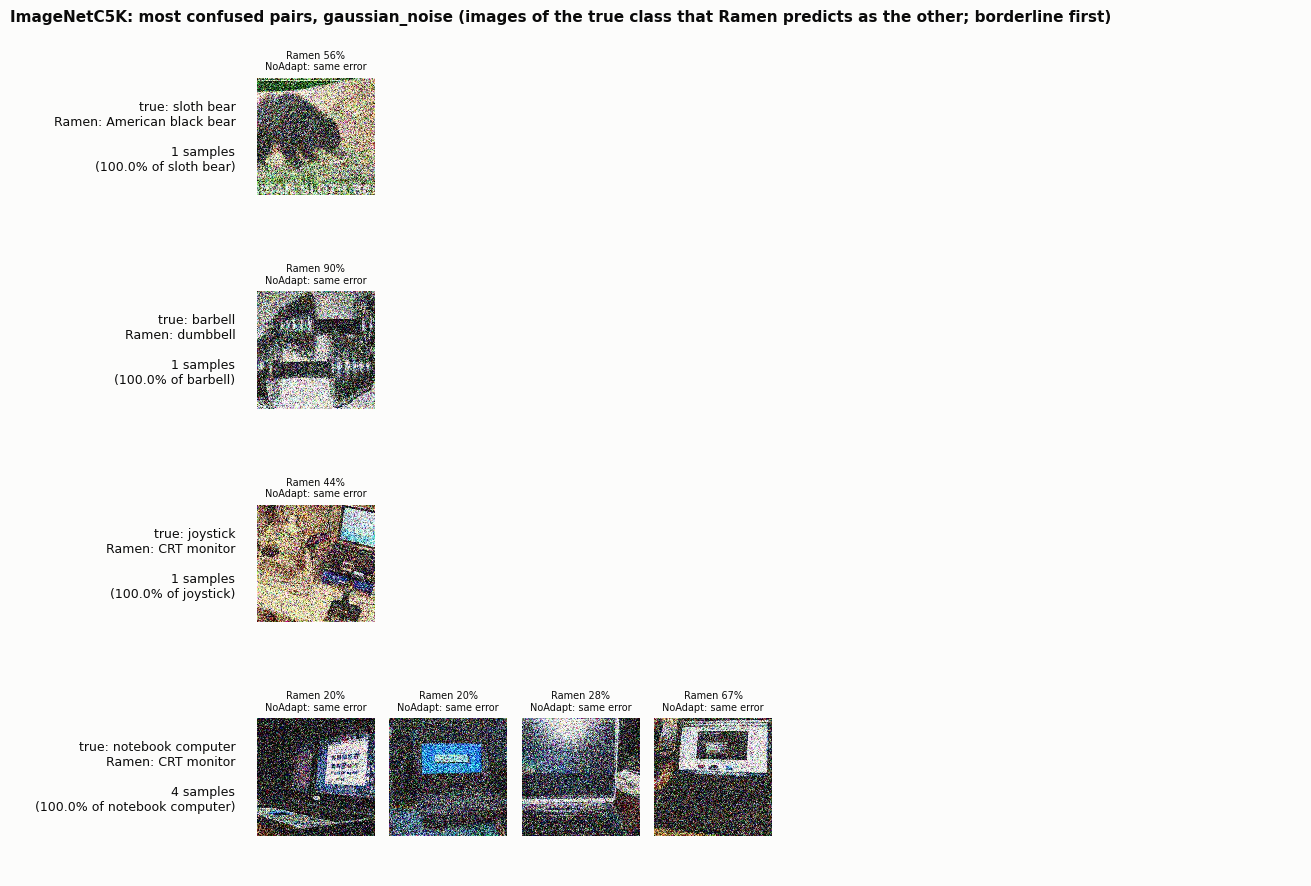

In [19]:
exp.show_confused_pairs(domain=worst, top_k=4, n=8, order='borderline');

## 9. Would "keep zero-shot when it is confident" help?
Post-hoc gate: use NoAdapt's prediction wherever its confidence is at least `tau`, and Ramen's elsewhere. This is exact for a gate that only skips a sample's own update, because the memory doesn't change. `oracle` is the ceiling for *any* per-sample choice between the two methods.

In [20]:
gate = exp.gate_sweep()
print(f"Ramen: {gate.attrs['Ramen']:.2f}   oracle (either right): {gate.attrs['oracle']:.2f}")
gate

Ramen: 33.08   oracle (either right): 36.90


,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,
0.50,21.54,67.92,68.70,32.91,318,443
0.60,16.11,74.50,74.66,33.05,142,161
0.70,11.80,80.33,80.40,33.07,56,62
0.80,8.02,85.51,85.47,33.08,19,17
0.90,4.36,90.65,90.62,33.08,5,4
0.95,2.37,94.15,94.15,33.08,2,2
0.99,0.49,98.65,98.92,33.08,0,1


## 10. Would "don't adapt when zero-shot entropy is already low" help?
Same post-hoc gate as section 9, but the signal is zero-shot **entropy** instead of confidence: use NoAdapt's prediction wherever its entropy is at most `tau · ln C`, and Ramen's elsewhere. `ln C` is the largest possible entropy (all classes equally likely), so `tau` is a fraction of it and the same `tau` values work for any number of classes. `entropy threshold` is the cut-off in nats (`ln 1000 ≈ 6.91` here). Low `tau` gates only the samples zero-shot is very sure about. (EATA uses the same scale, `0.4 · ln C`, for the opposite rule: it skips *high*-entropy samples.)
The columns mean the same as in section 9:
- `gated %`: share of samples kept at zero-shot.
- `broken saved`: gated samples where Ramen was wrong and zero-shot right.
- `fixed lost`: gated samples where Ramen was right and zero-shot wrong.
- Compare `gated total acc` with Ramen's accuracy printed above the table.

In [4]:
entropy_gate = exp.entropy_gate_sweep()   # taus=(0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6) by default
print(f"Ramen: {entropy_gate.attrs['Ramen']:.2f}   oracle (either right): {entropy_gate.attrs['oracle']:.2f}")
entropy_gate

Ramen: 33.08   oracle (either right): 36.90


,entropy threshold,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,,
0.05,0.345,2.51,93.61,93.61,33.08,2,2
0.10,0.691,5.33,88.25,88.18,33.08,12,9
0.20,1.382,13.12,76.11,76.89,32.98,183,260
0.30,2.072,22.42,65.04,66.54,32.74,556,807
0.40,2.763,33.68,55.30,57.84,32.22,1049,1690
0.50,3.454,45.50,47.57,50.93,31.55,1577,2724
0.60,4.145,58.04,41.17,45.53,30.55,1999,3896
